# RAG Baseline vs Cross-Encoder Re-Ranking
## Assignment 1 — Language Models and Agents

---

## Section 0 — Objective and Experiment Design

### Research Question
> Does Cross-Encoder re-ranking improve the placement of relevant chunks — and therefore the quality of LLM answers — compared with selecting the dense Top-3 directly?

### Why this matters (first principles)

A RAG system works in two stages:
1. **Retrieve** — find chunks of text that might answer the question
2. **Generate** — give those chunks to an LLM to produce an answer

If stage 1 retrieves the *wrong* chunks, no amount of cleverness in stage 2 can fix it.
The LLM can only work with what it is given.

### The two pipelines

```
PDF → chunks → embeddings
                    │
            Bi-Encoder retrieves Top-10
                    │
         ┌──────────┴──────────┐
         │                     │
   Pipeline A (Baseline)   Pipeline B (Re-ranked)
   Take first 3            Cross-Encoder rescores Top-10
         │                 → re-sorted Top-3
         │                     │
      Answer 1             Answer 2
```

### Controlled variables (identical in both pipelines)
| Variable | Value |
|---|---|
| Document | MCC Laws of Cricket (2017) |
| Chunking | size=150 words, overlap=30 words |
| Embedding model | all-MiniLM-L6-v2 |
| Candidate pool | Top-10 dense results |
| Final context size | Top-3 chunks |
| LLM | google/gemma-3-1b-it |
| Prompt template | Identical |
| Generation | Greedy (deterministic) |

### Independent variable (the one thing that changes)
> Whether the dense Top-10 are re-ranked by a Cross-Encoder before the final Top-3 are selected.

### Why the same Top-10 must feed both pipelines
If we retrieved a fresh Top-10 for each pipeline, any answer difference could come from
a different retrieval order — not from re-ranking. That would be a **confounding variable**.
By using the same Top-10 for both, we ensure re-ranking is the only thing that can change the result.

## Section 1 — Environment and Reproducibility

In [1]:
import platform
import torch
import sentence_transformers

print("Python         :", platform.python_version())
print("PyTorch        :", torch.__version__)
print("SentenceTransf :", sentence_transformers.__version__)
print("CUDA available :", torch.cuda.is_available())
print("Device         :", "cuda" if torch.cuda.is_available() else "cpu")

Python         : 3.14.6
PyTorch        : 2.13.0+cpu
SentenceTransf : 6.1.0
CUDA available : False
Device         : cpu


In [2]:
# Reproducibility: fix random seeds so every run gives the same results.
# Without this, tiny differences in random numbers could change results between runs.
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"All random seeds fixed to {SEED}")

All random seeds fixed to 42


In [3]:
# All experiment settings in one place.
# Keeping constants here means you only change one cell to try different settings.
import os

PDF_PATH        = os.path.join(os.getcwd(), "1638283934_MCC Laws of Cricket.pdf")
MODEL_CACHE     = os.path.join(os.getcwd(), "models")

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"   # bi-encoder
RERANKER_MODEL  = "cross-encoder/ms-marco-MiniLM-L-6-v2"     # cross-encoder
LLM_NAME        = "google/gemma-3-1b-it"

CHUNK_SIZE      = 150   # words per chunk
CHUNK_OVERLAP   = 30    # words shared between consecutive chunks
TOP_K_DENSE     = 10    # candidates retrieved by bi-encoder (same pool for both pipelines)
FINAL_K         = 3     # chunks sent to LLM

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device      : {DEVICE}")
print(f"Chunk size  : {CHUNK_SIZE} words, overlap {CHUNK_OVERLAP} words")
print(f"Retrieval   : Top-{TOP_K_DENSE} candidates -> final Top-{FINAL_K} to LLM")

Device      : cpu
Chunk size  : 150 words, overlap 30 words
Retrieval   : Top-10 candidates -> final Top-3 to LLM


## Section 2 — PDF Extraction

### Why extract page by page?
We keep the page number with each piece of text so we can:
1. **Cite sources** — tell the reader which page the evidence came from
2. **Debug** — go back to the PDF and verify any answer manually

We use **PyMuPDF** which extracts text as Unicode, preserving numbers,
punctuation, and negation words like 'not', 'except', 'shall not' —
all critical in cricket laws.

In [4]:
import pymupdf as fitz

def extract_pdf(path):
    """Open a PDF and return a list of dicts, one per page."""
    doc = fitz.open(path)
    pages = []
    for i, page in enumerate(doc):
        pages.append({"page": i + 1, "text": page.get_text()})
    doc.close()
    return pages

pages = extract_pdf(PDF_PATH)

total_words = sum(len(p["text"].split()) for p in pages)
empty_pages = [p["page"] for p in pages if len(p["text"].strip()) < 20]

print(f"Pages extracted : {len(pages)}")
print(f"Total words     : {total_words:,}")
print(f"Empty pages     : {empty_pages if empty_pages else 'none'}")
# Integer division gives an approximate estimate; build_chunks may produce one more
# chunk when the last partial window at a page boundary is counted separately.
print(f"Estimated chunks: ~{total_words // (CHUNK_SIZE - CHUNK_OVERLAP)} (approx; actual may differ by 1)")

Pages extracted : 168
Total words     : 36,832
Empty pages     : [166, 167, 168]
Estimated chunks: ~306 (approx; actual may differ by 1)


In [5]:
# Spot-check: verify numbers, negation words, and headings are preserved.
for label, idx in [("First", 0), ("Middle", len(pages)//2), ("Last", len(pages)-1)]:
    print(f"\n{'='*60}\n{label} -- Page {pages[idx]['page']}\n{'='*60}")
    print(pages[idx]["text"][:800])


First -- Page 1
THE 
LAWS OF CRICKET
(2017 Code)
OFFICIAL
© Marylebone Cricket Club 2017
World Copyright Reserved
Copies may be obtained from: 
Marylebone Cricket Club
(Lord's Shop), 
Lord's Cricket Ground, 
London NW8 8QN


Middle -- Page 85
85
LAW 27 THE WICKET-KEEPER
27.1 Protective equipment
	
The wicket-keeper is the only fielder permitted to wear 
gloves and external leg guards. If these are worn, they are 
to be regarded as part of his/her person for the purposes 
of Law 28.2 (Fielding the ball). If by the wicket-keeper’s 
actions and positioning when the ball comes into play it 
is apparent to the umpires that he/she will not be able to 
carry out the normal duties of a wicket-keeper, he/she shall 
forfeit this right and also the right to be recognised as a 
wicket-keeper for the purposes of Laws 33.2 (A fair catch), 
39 (Stumped), 28.1 (Protective equipment), 28.4 (Limitation 
of on-side fielders) and 28.5 (Fielders not to encroach 
on pitch).
27.2 Gloves
27.2.1 	
If, as pe

In [6]:
# Count key qualifiers — these create the difficult retrieval cases.
full_text = " ".join(p["text"] for p in pages)
for q in ["shall not", "except", "unless", "only if", "not permitted",
          "no more than", "provided that"]:
    print(f"  {q!r:25s}: {full_text.lower().count(q):>4} occurrences")

  'shall not'              :   86 occurrences
  'except'                 :   61 occurrences
  'unless'                 :   45 occurrences
  'only if'                :    9 occurrences
  'not permitted'          :    2 occurrences
  'no more than'           :    2 occurrences
  'provided that'          :   12 occurrences


## Section 3 — Chunking

### Why chunk? (first principles)

The whole document is ~37,000 words. We cannot send it all to the LLM because:
- LLMs have a fixed context window limit
- Longer prompts are slower and more expensive
- Models struggle to find a specific fact buried in a very long context

So we split into small pieces and only send the most relevant ones.

### Why overlap?

A boundary between chunks is arbitrary and can cut a sentence in half:
```
Chunk 42 ends:   "...the bowler shall not bowl more than"
Chunk 43 starts: "one over in succession in a match."
```
Neither chunk alone contains the complete rule.
With overlap=30, those 30 words appear in **both** chunks,
so at least one will contain the complete sentence.

### Trade-off
- **Too small** (e.g. 30 words): chunks lose context
- **Too large** (e.g. 500 words): one embedding must represent many topics
- **150 words** is a reasonable middle ground for a structured rules document

In [7]:
def build_chunks(pages, chunk_size=150, overlap=30):
    """
    Split the whole document into overlapping word-windows.

    Key design: flatten ALL pages into one word list first, THEN chunk.
    If we chunked page-by-page, a sentence split across a page boundary
    would lose overlap -- the last chunk of page N and first of page N+1
    would share nothing. Flattening first guarantees overlap everywhere.

    Each word carries its source page number so we can still cite pages.
    The chunk's page = page of its first word.

    step = chunk_size - overlap
    The window advances by `step` words each time, so the last `overlap`
    words of chunk N become the first `overlap` words of chunk N+1.
    """
    # Build one flat list of (word, page_number) pairs across the whole document
    all_words = []
    for page in pages:
        for word in page["text"].split():
            all_words.append((word, page["page"]))

    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(all_words), step):
        end = min(start + chunk_size, len(all_words))
        word_slice = all_words[start:end]
        chunks.append({
            "chunk_id"  : len(chunks),
            "page"      : word_slice[0][1],          # page of the first word
            "text"      : " ".join(w for w, _ in word_slice),
            "start_word": start,
            "end_word"  : end
        })
        if end == len(all_words):
            break

    return chunks


chunks = build_chunks(pages, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP)

assert CHUNK_OVERLAP < CHUNK_SIZE,             "Overlap must be smaller than chunk size"
assert len(chunks) > 10,                       "Too few chunks -- check PDF extraction"
assert all(c["text"].strip() for c in chunks), "Some chunks are empty"

print(f"Total chunks : {len(chunks)}")
print(f"Step size    : {CHUNK_SIZE - CHUNK_OVERLAP} words per advance")

Total chunks : 307
Step size    : 120 words per advance


In [8]:
# Verify overlap: the last ~30 words of chunk N should appear at the start of chunk N+1.
sample = 40
for offset in [0, 1]:
    c = chunks[sample + offset]
    print(f"\n--- Chunk {c['chunk_id']} | Page {c['page']} ---")
    print(c["text"])
print("\n(The text near the boundary should repeat across both chunks above.)")


--- Chunk 40 | Page 24 ---
the centres of the two middle stumps and shall be considered to be unlimited in length. 25 7.4 The return creases The return creases, which are the inside edges of the crease markings, shall be at right angles to the popping crease at a distance of 4 ft 4 in/1.32 m either side of the imaginary line joining the centres of the two middle stumps. Each return crease shall be marked from the popping crease to a minimum of 8 ft/2.44 m behind it and shall be considered to be unlimited in length. LAW 8 THE WICKETS 8.1 Description, width and pitching Two sets of wickets shall be pitched opposite and parallel to each other in the centres of the bowling creases. Each set shall be 9 in/22.86 cm wide and shall consist of three wooden stumps with two wooden bails on top. See Appendix D. 8.2 Size of stumps

--- Chunk 41 | Page 25 ---
bowling creases. Each set shall be 9 in/22.86 cm wide and shall consist of three wooden stumps with two wooden bails on top. See Appendix D

## Section 4 — Bi-Encoder Indexing

### What is an embedding? (first principles)

An embedding model converts text into a list of numbers (a **vector**).
Texts with similar *meaning* get similar vectors, even if they use different words:
```
"the batsman is out"       -> [0.12, -0.34, 0.87, ...]   (384 numbers)
"the batter is dismissed"  -> [0.11, -0.33, 0.89, ...]   (very similar!)
"tomorrow's weather"       -> [-0.5,  0.21, -0.4, ...]   (very different)
```

### Why L2-normalise?
After normalisation every vector has length 1. Then:
```
cosine_similarity(q, d) = q . d / (||q|| x ||d||) = q . d / (1 x 1) = q . d
```
Similarity becomes a simple dot product — one matrix multiply scores all chunks at once.

### Why is the bi-encoder fast?
Chunks are embedded **once** (offline, before any query).
At query time only the query is embedded — chunks are never re-embedded.

In [9]:
from sentence_transformers import SentenceTransformer

print("Loading embedding model...")
embedder = SentenceTransformer(EMBEDDING_MODEL, cache_folder=MODEL_CACHE, device=DEVICE)

print(f"Embedding {len(chunks)} chunks...")
chunk_embeddings = embedder.encode(
    [c["text"] for c in chunks],
    normalize_embeddings=True,
    show_progress_bar=True,
    batch_size=64
)

print(f"\nIndex shape : {chunk_embeddings.shape}")
print(f"  -> {chunk_embeddings.shape[0]} chunks x {chunk_embeddings.shape[1]} dimensions")
print(f"Norm check  : {np.linalg.norm(chunk_embeddings[0]):.6f}  (should be 1.000000)")

Loading embedding model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding 307 chunks...


Batches:   0%|          | 0/5 [00:00<?, ?it/s]


Index shape : (307, 384)
  -> 307 chunks x 384 dimensions
Norm check  : 1.000000  (should be 1.000000)


## Section 5 — LLM Loading and Shared Utilities

### Why both pipelines use the same prompt template

Both pipelines use the same prompt template, LLM and decoding settings.
The only thing that differs between them is which three chunks are passed as context,
because Pipeline B reorders the same dense Top-10 candidates before selecting the Top-3.

This means any difference in answers comes from a difference in the retrieved context
passages, not from a difference in the question, instructions, or model settings.

The prompt instructs the LLM to:
1. Answer **only** from the supplied context passages (reduces unsupported guesses)
2. Say which passage it used (makes the answer checkable)
3. Say "Not available in the supplied context" if the context is not enough (honest abstention)

In [10]:
import warnings, textwrap
from IPython.display import display, Markdown
from transformers import AutoTokenizer, AutoModelForCausalLM, GenerationConfig
from transformers.utils import logging as hf_logging
warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(LLM_NAME, cache_dir=MODEL_CACHE)

print("Loading LLM weights (this takes ~30s on CPU)...")
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME,
    cache_dir=MODEL_CACHE,
    torch_dtype=torch.bfloat16,
    **{"device_map": "cuda"} if DEVICE == "cuda" else {}
).to(DEVICE)

# do_sample=False = greedy decoding: always pick the most likely next token.
# This makes generation deterministic -- same input always gives same output.
llm.generation_config = GenerationConfig(
    max_new_tokens=350,
    do_sample=False,
    eos_token_id=llm.generation_config.eos_token_id
)
print("LLM ready.")

Loading tokenizer...


Loading LLM weights (this takes ~30s on CPU)...


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

LLM ready.


In [ ]:
# Shared prompt -- used IDENTICALLY in both pipelines.
# The only thing that changes between pipeline A and B is which 3 chunks fill {context}.
PROMPT_TEMPLATE = """You are an expert on the MCC Laws of Cricket.
Answer the question using ONLY the context passages supplied below.
Cite the passages you used, like [1] or [2].
If the context does not contain enough information, say exactly:
"Not available in the supplied context."

Context:
{context}

Question: {question}

Answer:"""


def build_prompt(question, context_chunks):
    """Format the prompt with numbered context chunks."""
    context_text = "\n\n".join(
        f"[{i+1}] (Chunk {c['chunk_id']}, Page {c['page']})\n{c['text']}"
        for i, c in enumerate(context_chunks)
    )
    return PROMPT_TEMPLATE.format(context=context_text, question=question)


def generate(prompt):
    """Send a prompt to the LLM and return its text reply."""
    messages = [{"role": "user", "content": prompt}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True,
        return_tensors="pt", return_dict=True
    ).to(DEVICE)
    with torch.no_grad():
        output = llm.generate(**inputs, max_new_tokens=400, do_sample=False)
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


def wrap(text, width=100):
    return "\n".join(textwrap.fill(line, width) for line in text.splitlines())


# Intentional hallucination demo (no context provided to the LLM).
# This shows what the LLM says when called directly without any retrieved context.
# The wrong answer ("baseball") is expected -- it demonstrates WHY RAG is needed.
# All subsequent cells use build_prompt() which always supplies retrieved context.
print("Testing LLM without context (hallucination demo)...")
print(generate("In one sentence: what sport do the MCC Laws govern?"))
print()
print("Note: the wrong answer above is deliberate. The LLM has no context here.")
print("With retrieved context, the model can produce grounded answers, evaluated below.")

## Section 6 — Pipeline A: Baseline (Dense Top-10 → first Top-3)

### How dense retrieval works step by step

1. Embed the query → query vector (384 numbers)
2. Dot-product with every chunk vector simultaneously (matrix multiply)
3. Each result is the cosine similarity between the query and that chunk
4. Sort descending → top-10 most similar chunks

```
query vector  (1 x 384)
      @
chunk matrix  (307 x 384)
      =
score vector  (307,)   <- one similarity score per chunk
```

Pipeline A takes the **first 3** of the top-10 — no further processing.

In [12]:
def retrieve_top10(query):
    """
    Return the Top-10 chunks most similar to the query.
    Adds dense_rank (1=best) and dense_score to each chunk dict.
    """
    q_vec  = embedder.encode(query, normalize_embeddings=True)
    scores = chunk_embeddings @ q_vec          # (n_chunks,) similarity scores
    top10  = np.argsort(-scores)[:TOP_K_DENSE] # indices of top-10
    return [
        {**chunks[idx], "dense_rank": r + 1, "dense_score": float(scores[idx])}
        for r, idx in enumerate(top10)
    ]


def show_candidates(candidates, n_chars=110):
    """Pretty-print candidates with dense and (if present) re-rank info."""
    for c in candidates:
        rerank_info = ""
        if "rerank_rank" in c:
            s = c["rank_shift"]
            arrow = f"up{s}" if s > 0 else (f"dn{abs(s)}" if s < 0 else "=")
            rerank_info = f" | re:{c['rerank_rank']:2d}({arrow}) xscore:{c['cross_score']:.2f}"
        print(
            f"  d:{c['dense_rank']:2d} s:{c['dense_score']:.3f}{rerank_info}"
            f" | ck{c['chunk_id']:3d} p{c['page']:3d} | {c['text'][:n_chars]}..."
        )


def run_baseline(query, verbose=True):
    """
    Pipeline A: retrieve Top-10, take first 3, generate Answer 1.
    Returns (candidates, baseline_top3, answer1) so Pipeline B can reuse candidates.
    """
    candidates    = retrieve_top10(query)
    baseline_top3 = candidates[:FINAL_K]
    answer1       = generate(build_prompt(query, baseline_top3))
    if verbose:
        print(f"Query: {query}\n")
        print("Top-10 (dense):")
        show_candidates(candidates)
        print(f"\nBaseline Top-3: chunks {[c['chunk_id'] for c in baseline_top3]}")
        print(f"\nAnswer 1 (Baseline):\n{wrap(answer1)}")
    return candidates, baseline_top3, answer1


# Smoke test
_ = run_baseline("How many players are on each cricket team?")

Query: How many players are on each cricket team?

Top-10 (dense):
  d: 1 s:0.549 | ck  7 p  6 | CONTENTS The Preamble:  The Spirit of Cricket Law 1: The players Law 2: The umpires Law 3: The scorers Law 4:...
  d: 2 s:0.534 | ck271 p142 | Member of the fielding side is one of the players nominated by the captain of the fielding side, or any autho...
  d: 3 s:0.517 | ck269 p141 | will be bowler’s end umpire and striker’s end umpire in alternate overs. A5.2 Bowler’s end umpire is the ump...
  d: 4 s:0.508 | ck 10 p  8 | team-mates, opponents and the authority of the umpires. Play hard and play fair. Accept the umpire’s decisio...
  d: 5 s:0.506 | ck270 p142 | or any authorised replacement for such nominated player. A6.3 A batsman’s ground – at each end of the pitch,...
  d: 6 s:0.502 | ck  2 p  2 | a fair balance between bat and ball, to make the Laws easier to understand, to safeguard players’ welfare, and...
  d: 7 s:0.486 | ck291 p156 | 4.5 Ball lost or becoming unfit for pl

## Section 7 — Pipeline B: Cross-Encoder Re-Ranking

### Bi-Encoder vs Cross-Encoder (first principles)

**Bi-Encoder** (used in Section 6):
```
query  --> encoder --> vector Q
chunk  --> encoder --> vector D
score  = Q . D
```
Each text is encoded *independently* — the chunk does not know what the query is.
Subtle differences (negation, exceptions, specific names) can get lost because
both texts are compressed into a fixed-size vector before being compared.

**Cross-Encoder** reads them *together*:
```
[CLS] query [SEP] chunk [SEP]  ->  transformer  ->  relevance score
```
The Cross-Encoder reads the query and the chunk at the same time and gives a
single relevance score. Because both texts are read together, the model can notice:
- "wicket-keeper" in the query matches "wicket-keeper" specifically (not just "fielder")
- "shall NOT" changes the meaning of an otherwise similar sentence
- Multiple conditions in the query all appear together in the relevant chunk

### Why not cross-encode everything?
For N chunks, the Cross-Encoder must evaluate N query-chunk pairs.
Some systems batch several pairs into one model call for speed, but the total
amount of work still grows with N. For a large document collection this quickly
becomes too slow to use in practice.
So we only cross-encode the 10 candidates the bi-encoder already selected.

### Warning: scores are not comparable across models
Dense scores are cosine similarities (roughly 0–1).
Cross-Encoder scores are raw numbers (can be any value, positive or negative).
Only the **rank order within each model** is meaningful.

In [13]:
from sentence_transformers import CrossEncoder

print("Loading Cross-Encoder...")
reranker = CrossEncoder(RERANKER_MODEL, device=DEVICE)
print("Done.")


def rerank_candidates(query, candidates):
    """
    Score each (query, chunk) pair with the Cross-Encoder and re-sort.

    IMPORTANT: `candidates` must be the SAME Top-10 from retrieve_top10().
    Do not call retrieve_top10() again -- that would change the candidate pool.

    rank_shift = dense_rank - rerank_rank
      positive -> moved up (good for relevant chunks)
      negative -> moved down
      zero     -> unchanged
    """
    pairs  = [(query, c["text"]) for c in candidates]
    scores = reranker.predict(pairs)

    reranked = [{**c, "cross_score": float(s)} for c, s in zip(candidates, scores)]
    reranked.sort(key=lambda x: x["cross_score"], reverse=True)

    for new_rank, item in enumerate(reranked, start=1):
        item["rerank_rank"] = new_rank
        item["rank_shift"]  = item["dense_rank"] - new_rank

    return reranked


def run_reranked(query, candidates, verbose=True):
    """
    Pipeline B: re-rank the SAME Top-10, take new Top-3, generate Answer 2.
    `candidates` must come from run_baseline() -- NOT a fresh retrieval.
    """
    reranked      = rerank_candidates(query, candidates)
    reranked_top3 = reranked[:FINAL_K]
    answer2       = generate(build_prompt(query, reranked_top3))
    if verbose:
        print(f"Query: {query}\n")
        print("Top-10 after re-ranking:")
        show_candidates(reranked)
        print(f"\nRe-ranked Top-3: chunks {[c['chunk_id'] for c in reranked_top3]}")
        print(f"\nAnswer 2 (Re-ranked):\n{wrap(answer2)}")
    return reranked, reranked_top3, answer2


# Smoke test -- reuse candidates from Section 6
smoke_cands, _, _ = run_baseline("How many players are on each cricket team?", verbose=False)
run_reranked("How many players are on each cricket team?", smoke_cands);

Loading Cross-Encoder...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Done.


Query: How many players are on each cricket team?

Top-10 after re-ranking:
  d: 2 s:0.534 | re: 1(up1) xscore:-3.89 | ck271 p142 | Member of the fielding side is one of the players nominated by the captain of the fielding side, or any autho...
  d: 4 s:0.508 | re: 2(up2) xscore:-3.90 | ck 10 p  8 | team-mates, opponents and the authority of the umpires. Play hard and play fair. Accept the umpire’s decisio...
  d:10 s:0.482 | re: 3(up7) xscore:-4.47 | ck  9 p  7 | bat) Appendix C: Laws 6 (The pitch) and 7 (The creases) Appendix D: Law 8 (The wickets) Appendix E: Wicket-...
  d: 1 s:0.549 | re: 4(dn3) xscore:-6.31 | ck  7 p  6 | CONTENTS The Preamble:  The Spirit of Cricket Law 1: The players Law 2: The umpires Law 3: The scorers Law 4:...
  d: 6 s:0.502 | re: 5(up1) xscore:-6.52 | ck  2 p  2 | a fair balance between bat and ball, to make the Laws easier to understand, to safeguard players’ welfare, and...
  d: 5 s:0.506 | re: 6(dn1) xscore:-7.02 | ck270 p142 | or any authorised 

## Section 8 — Evaluation Queries

### Three categories of queries

**Category A — Sanity checks:** simple direct questions to verify the pipeline works.

**Category B — Stress tests:** designed to expose known bi-encoder weaknesses:
- *Negation:* "When is X NOT allowed?" — positive rules may score higher than the restriction
- *Exception:* "What happens in [special case]?" — exception chunk may rank below general rule
- *Similar entity:* "Rules for [role A]?" — chunks about [role B] share vocabulary
- *Multiple constraints:* query requires two conditions met simultaneously

**Category C — Discovered failures:** cases where the relevant chunk sits at dense rank 4-10
but the Cross-Encoder promotes it into the Top-3.

### Ground truth
For every query we manually record the correct answer and supporting page.
This lets us judge whether Answer 1 and Answer 2 are actually correct — not just different.

In [14]:
evaluation_queries = [
    # Category A: Sanity checks
    {
        "id": "Q01", "category": "A",
        "query": "How many players are on each cricket team?",
        "answer_summary": "11 players per side",
        "failure_type": "sanity check"
    },
    {
        "id": "Q02", "category": "A",
        "query": "How many balls are in one over?",
        "answer_summary": "6 fair deliveries",
        "failure_type": "sanity check"
    },
    {
        "id": "Q03", "category": "A",
        "query": "What is the follow-on in cricket and when can it be enforced?",
        "answer_summary": "Team batting 2nd forced to bat again if deficit exceeds threshold",
        "failure_type": "sanity check"
    },

    # Category B: Stress tests
    {
        "id": "Q04", "category": "B",
        "query": "Can a bowler who completed the previous over bowl any part of the next over?",
        "answer_summary": "No; a bowler cannot bowl two consecutive overs (Law 17.6)",
        "failure_type": "negation -- consecutive-over restriction may be outranked by general bowling rules"
    },
    {
        "id": "Q05", "category": "B",
        "query": "What fielding equipment is the wicket-keeper allowed to wear that other fielders cannot?",
        "answer_summary": "Only wicket-keeper may wear gloves and external leg guards",
        "failure_type": "similar entity -- general fielder vs wicket-keeper rules"
    },
    {
        "id": "Q06", "category": "B",
        "query": "How many penalty runs are awarded if the ball strikes a protective helmet placed on the ground by the fielding side?",
        "answer_summary": "5 penalty runs are awarded to the batting side (Law 28.3.2)",
        "failure_type": "direct fact -- both pipelines expected to succeed"
    },
    {
        "id": "Q07", "category": "B",
        "query": "What is the restriction on fielders allowed on the leg side behind the popping crease?",
        "answer_summary": "No more than 2 fielders behind popping crease on leg side at moment of delivery",
        "failure_type": "numerical constraint with condition"
    },
    {
        "id": "Q08", "category": "B",
        "query": "When is a delivery called a No ball because of the bowler's bowling action?",
        "answer_summary": "A delivery is called No ball for throwing if the bowler's elbow joint straightens partially or completely after the arm reaches shoulder level during the delivery swing, until the ball leaves the hand (Law 21.2).",
        "failure_type": "multiple conditions -- wide ball rules may compete"
    },

    # Category C: Discovered failures
    {
        "id": "Q09", "category": "C",
        "query": "What makes a catch invalid if the fielder is near the boundary?",
        "answer_summary": "Fielder must not touch or ground over boundary while completing catch",
        "failure_type": "exception -- general catch rules vs boundary conditions"
    },
    {
        "id": "Q10", "category": "C",
        "query": "Under what conditions is a batter not out for Obstructing the field?",
        "answer_summary": "When the obstruction was accidental or to avoid injury (Law 37.2)",
        "failure_type": "negation + exception combined"
    },
    {
        "id": "Q11", "category": "C",
        "query": "Under what conditions are leg byes not scored?",
        "answer_summary": "When the striker neither attempted to play the ball nor tried to avoid being hit (Law 23.3)",
        "failure_type": "negation -- not-awarded condition buried below wide/no-ball chunks"
    },
]

print(f"Evaluation set: {len(evaluation_queries)} queries")
for q in evaluation_queries:
    print(f"  [{q['id']}] ({q['category']}) {q['query']}")


Evaluation set: 11 queries
  [Q01] (A) How many players are on each cricket team?
  [Q02] (A) How many balls are in one over?
  [Q03] (A) What is the follow-on in cricket and when can it be enforced?
  [Q04] (B) Can a bowler who completed the previous over bowl any part of the next over?
  [Q05] (B) What fielding equipment is the wicket-keeper allowed to wear that other fielders cannot?
  [Q06] (B) How many penalty runs are awarded if the ball strikes a protective helmet placed on the ground by the fielding side?
  [Q07] (B) What is the restriction on fielders allowed on the leg side behind the popping crease?
  [Q08] (B) When is a delivery called a No ball because of the bowler's bowling action?
  [Q09] (C) What makes a catch invalid if the fielder is near the boundary?
  [Q10] (C) Under what conditions is a batter not out for Obstructing the field?
  [Q11] (C) Under what conditions are leg byes not scored?


In [15]:
# Run both pipelines on all queries.
# Both pipelines share the SAME Top-10 candidates -- guaranteed by passing
# `candidates` from run_baseline() directly into run_reranked().
results = []

for eq in evaluation_queries:
    print(f"\n{'='*70}")
    print(f"[{eq['id']}] {eq['query']}")
    print(f"Expected : {eq['answer_summary']}")
    print(f"Type     : {eq['failure_type']}")
    print("="*70)

    candidates,   baseline_top3, answer1 = run_baseline(eq["query"], verbose=False)
    reranked, reranked_top3, answer2     = run_reranked(eq["query"], candidates, verbose=False)

    results.append({
        "query_id": eq["id"], "category": eq["category"],
        "query": eq["query"], "expected": eq["answer_summary"],
        "failure_type": eq["failure_type"],
        "candidates": candidates, "baseline_top3": baseline_top3,
        "reranked": reranked, "reranked_top3": reranked_top3,
        "answer1": answer1, "answer2": answer2,
    })

    display(Markdown(
        f"**Answer 1 (Baseline):**\n\n{answer1}\n\n---\n\n"
        f"**Answer 2 (Re-ranked):**\n\n{answer2}"
    ))


[Q01] How many players are on each cricket team?
Expected : 11 players per side
Type     : sanity check


**Answer 1 (Baseline):**

According to the provided text, “A7.3 Fielder is one of the 11 or fewer players who together represent the fielding side on the field of play. This definition includes not only both the bowler and the wicket-keeper but also nominated players who are 143 legitimately on the field of play, together with players legitimately acting as substitutes for absent nominated players. It excludes any nominated player who is absent from the field of play, or who has been absent from the field of play and who has not yet obtained the umpire’s permission to return.”

Therefore, there are 11 players on each fielding side.

---

**Answer 2 (Re-ranked):**

Not available in the supplied context.


[Q02] How many balls are in one over?
Expected : 6 fair deliveries
Type     : sanity check


**Answer 1 (Baseline):**

The text states: “The ball shall be bowled from each end alternately in overs of 6 balls.”

So, there are 6 balls in one over.

---

**Answer 2 (Re-ranked):**

The text states: “The ball shall be bowled from each end alternately in overs of 6 balls.”


[Q03] What is the follow-on in cricket and when can it be enforced?
Expected : Team batting 2nd forced to bat again if deficit exceeds threshold
Type     : sanity check


...

**Answer 1 (Baseline):**

According to the provided text, a catch is invalid if the fielder is near the boundary and is not grounded beyond the boundary before the catch is completed, as described in 33.2.2.2.

---

**Answer 2 (Re-ranked):**

According to the provided text, a catch is invalid if the fielder is grounded beyond the boundary if some part of his/her person is in contact with any of the following: the boundary or any part of an object used to mark the boundary; the ground beyond the boundary; any object that is in contact with the ground beyond the boundary; another fielder who is grounded beyond the boundary, if the umpire considers that it was the intention of either fielder that the contact should assist in the fielding of the ball.


[Q10] Under what conditions is a batter not out for Obstructing the field?
Expected : When the obstruction was accidental or to avoid injury (Law 37.2)
Type     : negation + exception combined


**Answer 1 (Baseline):**

According to the provided text, a batsman is not out for obstructing the field if obstruction or distraction is accidental, or in the case of the striker, he/she makes a second or subsequent strike to guard his/her wicket lawfully as in Law 34.3.

---

**Answer 2 (Re-ranked):**

According to the provided text, a batsman is not out for obstructing the field if obstruction or distraction is accidental, or in the case of the striker, he/she makes a second or subsequent strike to guard his/her wicket lawfully as in Law 34.3.


[Q11] Under what conditions are leg byes not scored?
Expected : When the striker neither attempted to play the ball nor tried to avoid being hit (Law 23.3)
Type     : negation -- not-awarded condition buried below wide/no-ball chunks


**Answer 1 (Baseline):**

According to the provided text, leg byes are not scored when the ball is dead. 2.13.1.3 states “The signals listed below shall be made to the scorers only when the ball is dead.”

---

**Answer 2 (Re-ranked):**

Under the circumstances outlined in the provided text, leg byes are not awarded if neither of the conditions therein has been met. Specifically, if the ball does not become dead for any other reason, or if the delivery is a No ball, then Leg byes shall not be awarded.

## Section 9 — Rank-Shift Analysis

### What rank shift means

```
rank_shift = dense_rank - rerank_rank

Example: chunk at dense rank 8, moved to rerank rank 1
rank_shift = 8 - 1 = +7  (moved UP 7 positions)
```

A **positive rank shift on the relevant chunk** means re-ranking worked.
It brought the correct evidence higher, potentially into the Top-3.

### What to look for in a strong failure case
1. Relevant chunk at dense rank 4-10 (outside baseline Top-3)
2. Cross-Encoder promotes it to rerank rank 1-3
3. Answer 1 is wrong or incomplete
4. Answer 2 is correct because the right evidence now reaches the LLM

### Warning
Do not compare dense scores and cross scores as magnitudes.
They come from different mathematical operations — only rank order matters.

In [16]:
import pandas as pd

def rank_shift_table(result):
    """Build a DataFrame showing how chunks moved between dense and re-ranked order."""
    baseline_ids = {c["chunk_id"] for c in result["baseline_top3"]}
    reranked_ids = {c["chunk_id"] for c in result["reranked_top3"]}
    rows = []
    for c in sorted(result["reranked"], key=lambda x: x["dense_rank"]):
        rows.append({
            "Chunk"        : c["chunk_id"],
            "Page"         : c["page"],
            "Dense rank"   : c["dense_rank"],
            "Dense score"  : round(c["dense_score"], 3),
            "Re-rank"      : c["rerank_rank"],
            "Cross score"  : round(c["cross_score"], 2),
            "Rank shift"   : c["rank_shift"],
            "Baseline T3?" : "YES" if c["chunk_id"] in baseline_ids else "-",
            "Rerank T3?"   : "YES" if c["chunk_id"] in reranked_ids else "-",
        })
    return pd.DataFrame(rows)


for r in results:
    print(f"\n{'='*70}")
    print(f"[{r['query_id']}] {r['query']}")
    print(f"Expected: {r['expected']}")
    display(rank_shift_table(r))


[Q01] How many players are on each cricket team?
Expected: 11 players per side


,Chunk,Page,Dense rank,Dense score,Re-rank,Cross score,Rank shift,Baseline T3?,Rerank T3?
0,7,6,1,0.549,4,-6.31,-3,YES,-
1,271,142,2,0.534,1,-3.89,1,YES,YES
2,269,141,3,0.517,8,-7.92,-5,YES,-
3,10,8,4,0.508,2,-3.90,2,-,YES
4,270,142,5,0.506,6,-7.02,-1,-,-
5,2,2,6,0.502,5,-6.52,1,-,-
6,291,156,7,0.486,9,-9.20,-2,-,-
7,288,152,8,0.486,10,-9.36,-2,-,-
8,30,19,9,0.485,7,-7.27,2,-,-
9,9,7,10,0.482,3,-4.47,7,-,YES



[Q02] How many balls are in one over?
Expected: 6 fair deliveries


,Chunk,Page,Dense rank,Dense score,Re-rank,Cross score,Rank shift,Baseline T3?,Rerank T3?
0,87,49,1,0.491,1,3.99,0,YES,YES
1,297,159,2,0.475,7,-2.25,-5,YES,-
2,86,48,3,0.474,2,2.47,1,YES,YES
3,88,49,4,0.465,3,1.20,1,-,YES
4,27,17,5,0.459,9,-3.89,-4,-,-
5,129,70,6,0.425,4,0.54,2,-,-
6,116,63,7,0.415,5,-0.59,2,-,-
7,28,18,8,0.411,10,-3.95,-2,-,-
8,295,158,9,0.410,6,-0.90,3,-,-
9,29,19,10,0.401,8,-2.47,2,-,-



[Q03] What is the follow-on in cricket and when can it be enforced?
Expected: Team batting 2nd forced to bat again if deficit exceeds threshold


...

,Chunk,Page,Dense rank,Dense score,Re-rank,Cross score,Rank shift,Baseline T3?,Rerank T3?
0,185,98,1,0.723,2,2.63,-1,YES,YES
1,183,97,2,0.717,3,2.08,-1,YES,YES
2,184,98,3,0.674,5,-0.48,-2,YES,-
3,107,59,4,0.656,1,2.74,3,-,YES
4,168,89,5,0.583,8,-4.56,-3,-,-
5,186,99,6,0.579,9,-5.46,-3,-,-
6,109,60,7,0.576,6,-2.02,1,-,-
7,108,59,8,0.573,4,-0.47,4,-,-
8,104,57,9,0.572,10,-6.68,-1,-,-
9,196,104,10,0.569,7,-3.17,3,-,-



[Q10] Under what conditions is a batter not out for Obstructing the field?
Expected: When the obstruction was accidental or to avoid injury (Law 37.2)


,Chunk,Page,Dense rank,Dense score,Re-rank,Cross score,Rank shift,Baseline T3?,Rerank T3?
0,196,104,1,0.623,1,5.71,0,YES,YES
1,143,77,2,0.614,7,-2.94,-5,YES,-
2,195,103,3,0.611,2,4.48,1,YES,YES
3,138,75,4,0.593,5,-1.97,-1,-,-
4,136,74,5,0.587,6,-2.14,-1,-,-
5,198,105,6,0.581,9,-4.44,-3,-,-
6,164,88,7,0.567,10,-5.14,-3,-,-
7,187,99,8,0.564,3,4.15,5,-,YES
8,142,76,9,0.560,8,-4.44,1,-,-
9,154,82,10,0.558,4,-1.26,6,-,-



[Q11] Under what conditions are leg byes not scored?
Expected: When the striker neither attempted to play the ball nor tried to avoid being hit (Law 23.3)


,Chunk,Page,Dense rank,Dense score,Re-rank,Cross score,Rank shift,Baseline T3?,Rerank T3?
0,298,160,1,0.615,8,1.19,-7,YES,-
1,133,72,2,0.597,6,2.25,-4,YES,-
2,22,15,3,0.595,10,-0.97,-7,YES,-
3,129,70,4,0.584,9,1.13,-5,-,-
4,299,160,5,0.576,5,2.70,0,-,-
5,134,73,6,0.566,3,4.31,3,-,YES
6,96,53,7,0.566,4,3.43,3,-,-
7,136,74,8,0.566,1,6.70,7,-,YES
8,135,73,9,0.565,2,4.40,7,-,YES
9,128,70,10,0.563,7,1.72,3,-,-


## Section 9b — Failure Case Deep Dives

For each failure case explain:
- **Why the bi-encoder failed** — what semantic signal it latched onto incorrectly
- **Why the Cross-Encoder succeeded** — what token-level interaction it could model
- **How the answer changed** — grounded in the rank shift, not speculation

> Connect answer differences to evidence differences.
> Do not say "Answer 2 was better" — say which specific chunk moved, why it moved,
> and how that chunk's content changed the answer.

A case counts as a genuine retrieval rescue when the correct chunk was outside the
baseline Top-3 and the cross-encoder promoted it into the re-ranked Top-3.
**Answer 2 becomes materially more relevant, correct, or complete because the rescued
evidence enters the Top-3** — it does not need to be fully correct to qualify.

In [17]:
# Failure Case 1: Q09 -- boundary catch exception query.
# ck107 (page 59, Law 19.5) was at dense rank 4; Cross-Encoder promoted it to rank 1 (shift = +3).
# ck107 was NOT in baseline Top-3 but IS in re-ranked Top-3. Genuine rescue.

FAILURE_CASE_1_ID = "Q09"
fc1 = next(r for r in results if r["query_id"] == FAILURE_CASE_1_ID)

print(f"Query   : {fc1['query']}")
print(f"Expected: {fc1['expected']}")

print(f"\n--- Dense Top-3 (what Pipeline A saw) ---")
for c in fc1["baseline_top3"]:
    print(f"  Chunk {c['chunk_id']} | Page {c['page']} | dense {c['dense_score']:.3f}")
    print(f"  {c['text'][:300]}\n")

print(f"--- Re-ranked Top-3 (what Pipeline B saw) ---")
for c in fc1["reranked_top3"]:
    print(f"  Chunk {c['chunk_id']} | Page {c['page']} | cross {c['cross_score']:.2f} "
          f"| rank {c['dense_rank']}->{c['rerank_rank']} (shift {c['rank_shift']:+d})")
    print(f"  {c['text'][:300]}\n")

print(f"--- Answer 1 (Baseline) ---")
print(wrap(fc1["answer1"]))
print(f"\n--- Answer 2 (Re-ranked) ---")
print(wrap(fc1["answer2"]))

Query   : What makes a catch invalid if the fielder is near the boundary?
Expected: Fielder must not touch or ground over boundary while completing catch

--- Dense Top-3 (what Pipeline A saw) ---
  Chunk 185 | Page 98 | dense 0.723
  crossed the boundary in the air, provided that the conditions in 33.2.1 are met. 33.2.2.5 the ball is caught off an obstruction within the boundary that is not designated a boundary by the umpires. 33.3 Making a catch The act of making a catch shall start from the time when the ball first comes in

  Chunk 183 | Page 97 | dense 0.717
  Out Caught The striker is out Caught if a ball delivered by the bowler, not being a No ball, touches his/her bat without having previously been in contact with any fielder, and is subsequently held by a fielder as a fair catch, as described in 33.2 and 33.3, before it touches the ground. 33.2 A fai

  Chunk 184 | Page 98 | dense 0.674
  following conditions applies: 33.2.2.1 the ball is held in the hand or hands of a fi

In [18]:
fc1_ck107 = next((c for c in fc1["reranked"] if c["chunk_id"] == 107), None)
fc1_ck107_cross = fc1_ck107["cross_score"] if fc1_ck107 else "n/a"
fc1_ck107_shift = fc1_ck107["rank_shift"]  if fc1_ck107 else "n/a"
fc1_ck107_drank = fc1_ck107["dense_rank"]  if fc1_ck107 else "n/a"
fc1_ck107_rrank = fc1_ck107["rerank_rank"] if fc1_ck107 else "n/a"

analysis_fc1 = f"""
FAILURE CASE 1: {fc1['query_id']}
Query   : {fc1['query']}
Expected: {fc1['expected']}
=====================================================

WHAT HAPPENED:
  Baseline Top-3 : {[c['chunk_id'] for c in fc1['baseline_top3']]}
  Re-ranked Top-3: {[c['chunk_id'] for c in fc1['reranked_top3']]}

  ck107 (page 59, Law 19.5 "Fielder grounded beyond the boundary"):
    Dense rank {fc1_ck107_drank} -> Re-rank {fc1_ck107_rrank}  (shift {fc1_ck107_shift:+d})
    Cross-score: {fc1_ck107_cross:.2f}
    NOT in baseline Top-3. IS in re-ranked Top-3. Genuine rescue.

WHY THE BI-ENCODER MISSED ck107:
  The bi-encoder encoded the query and all chunks independently, matching on
  general vocabulary: "catch", "boundary", "fielder". The top three chunks all
  contain these words in general catch/boundary contexts. ck107 (page 59) contains
  Law 19.5, the exact rule defining when a fielder's boundary contact invalidates
  a catch. At dense rank 4, it just missed the baseline Top-3.

WHY THE CROSS-ENCODER PROMOTED ck107:
  The cross-encoder encodes query and chunk jointly in one forward pass:
    [CLS] what makes a catch invalid near boundary [SEP] <chunk text> [SEP]
  The specific grounded-beyond-boundary conditions in ck107 matched the invalidity
  question far better than the general catch chunks. ck107 received the highest
  cross-score ({fc1_ck107_cross:.2f}) and moved to re-rank 1 (shift = {fc1_ck107_shift:+d}).

HOW THE ANSWER CHANGED:
  Answer 1 (Baseline, ck107 not in context):
  {fc1['answer1'][:400]}

  Answer 2 (Re-ranked, ck107 in Top-3):
  {fc1['answer2'][:400]}

KEY INSIGHT:
  The relevant chunk was only one rank outside the baseline Top-3 (rank 4 vs 3).
  The cross-encoder's joint encoding detected the specific boundary-grounding
  language and promoted ck107 to rank 1. Answer 2 closely follows the Law 19.5 definition; Answer 1 is vague and slightly backwards.
"""
print(analysis_fc1)


FAILURE CASE 1: Q09
Query   : What makes a catch invalid if the fielder is near the boundary?
Expected: Fielder must not touch or ground over boundary while completing catch

WHAT HAPPENED:
  Baseline Top-3 : [185, 183, 184]
  Re-ranked Top-3: [107, 185, 183]

  ck107 (page 59, Law 19.5 "Fielder grounded beyond the boundary"):
    Dense rank 4 -> Re-rank 1  (shift +3)
    Cross-score: 2.74
    NOT in baseline Top-3. IS in re-ranked Top-3. Genuine rescue.

WHY THE BI-ENCODER MISSED ck107:
  The bi-encoder encoded the query and all chunks independently, matching on
  general vocabulary: "catch", "boundary", "fielder". The top three chunks all
  contain these words in general catch/boundary contexts. ck107 (page 59) contains
  Law 19.5, the exact rule defining when a fielder's boundary contact invalidates
  a catch. At dense rank 4, it just missed the baseline Top-3.

WHY THE CROSS-ENCODER PROMOTED ck107:
  The cross-encoder encodes query and chunk jointly in one forward pass:
    [CLS] 

In [19]:
# Failure Case 2: Q11 -- leg byes not scored.
# ck136 (page 74, Law 23.3) was at dense rank 8; Cross-Encoder promoted it to rank 1 (shift = +7).
# ck136 was NOT in baseline Top-3 but IS in re-ranked Top-3. Genuine rescue.
# Baseline Top-3 consisted of index/table-of-contents chunks that could not answer the query.

FAILURE_CASE_2_ID = "Q11"
fc2 = next(r for r in results if r["query_id"] == FAILURE_CASE_2_ID)

print(f"Query   : {fc2['query']}")
print(f"Expected: {fc2['expected']}")

print(f"\n--- Dense Top-3 (what Pipeline A saw) ---")
for c in fc2["baseline_top3"]:
    print(f"  Chunk {c['chunk_id']} | Page {c['page']} | dense {c['dense_score']:.3f}")
    print(f"  {c['text'][:300]}\n")

print(f"--- Re-ranked Top-3 (what Pipeline B saw) ---")
for c in fc2["reranked_top3"]:
    print(f"  Chunk {c['chunk_id']} | Page {c['page']} | cross {c['cross_score']:.2f} "
          f"| rank {c['dense_rank']}->{c['rerank_rank']} (shift {c['rank_shift']:+d})")
    print(f"  {c['text'][:300]}\n")

print(f"--- Answer 1 (Baseline) ---")
print(wrap(fc2["answer1"]))
print(f"\n--- Answer 2 (Re-ranked) ---")
print(wrap(fc2["answer2"]))

Query   : Under what conditions are leg byes not scored?
Expected: When the striker neither attempted to play the ball nor tried to avoid being hit (Law 23.3)

--- Dense Top-3 (what Pipeline A saw) ---
  Chunk 298 | Page 160 | dense 0.615
  a delivery 21.10 Ball bouncing over head height of striker 21.11 Call of No ball for infringement of other Laws 21.12 Revoking a call of No ball 21.13 No ball to over-ride Wide 21.14 Ball not dead 21.15 Penalty for a No ball 21.16 Runs resulting from a No ball – how scored 21.17 No ball not to co

  Chunk 133 | Page 72 | dense 0.597
  be scored as Wide balls. Apart from any award of 5 Penalty runs, all runs resulting from a Wide shall be debited against the bowler. 22.8 Wide not to count A Wide shall not count as one of the over. See Law 17.3 (Validity of balls). 22.9 Out from a Wide When Wide ball has been called, neither bats

  Chunk 22 | Page 15 | dense 0.595
  out.) Wide – by extending both arms horizontally. 2.13.1.2 When the ball is dea

In [20]:
fc2_ck136 = next((c for c in fc2["reranked"] if c["chunk_id"] == 136), None)
fc2_ck136_cross = fc2_ck136["cross_score"] if fc2_ck136 else "n/a"
fc2_ck136_shift = fc2_ck136["rank_shift"]  if fc2_ck136 else "n/a"
fc2_ck136_drank = fc2_ck136["dense_rank"]  if fc2_ck136 else "n/a"
fc2_ck136_rrank = fc2_ck136["rerank_rank"] if fc2_ck136 else "n/a"

analysis_fc2 = f"""
FAILURE CASE 2: {fc2['query_id']}
Query   : {fc2['query']}
Expected: {fc2['expected']}
=====================================================

WHAT HAPPENED:
  Baseline Top-3 : {[c['chunk_id'] for c in fc2['baseline_top3']]}
  Re-ranked Top-3: {[c['chunk_id'] for c in fc2['reranked_top3']]}

  ck136 (page 74, Law 23.3 "Leg byes not to be awarded"):
    Dense rank {fc2_ck136_drank} -> Re-rank {fc2_ck136_rrank}  (shift {fc2_ck136_shift:+d})
    Cross-score: {fc2_ck136_cross:.2f}
    NOT in baseline Top-3. IS in re-ranked Top-3. Genuine rescue.

WHY THE BI-ENCODER PLACED ck136 AT RANK 8:
  The query asks when leg byes are not scored. The bi-encoder matched on
  surface vocabulary -- "leg byes", "not", "scored" -- but the top chunks were
  an index/contents page (ck298, p160), a wide-ball rules chunk (ck133, p72),
  and an umpire-signals chunk (ck22, p15). These share words like "scored",
  "not", and cricket terminology but contain no Law 23.3 content.
  ck136 (page 74) contains the Law 23.3 text describing when leg byes shall not
  be awarded. The dense similarity was not strong enough to promote it above the
  surface-vocabulary matches.

WHY THE CROSS-ENCODER PROMOTED ck136:
  The cross-encoder reads query and chunk jointly:
    [CLS] under what conditions are leg byes not scored [SEP] <chunk text> [SEP]
  The Law 23.3 not-awarded condition in ck136 directly matched the negative framing
  of the query. ck136 received cross-score {fc2_ck136_cross:.2f} and moved from dense
  rank {fc2_ck136_drank} to re-rank {fc2_ck136_rrank} (shift = {fc2_ck136_shift:+d}).

HOW THE ANSWER CHANGED:
  Answer 1 (Baseline, ck136 not in context):
  {fc2['answer1']}

  Answer 2 (Re-ranked, ck136 in Top-3):
  {fc2['answer2']}

  Answer 1 is factually wrong: it says "leg byes are not scored when the ball is
  dead", which confuses the umpire-signal rules (from index page ck298) with the
  actual leg-bye scoring condition.
  Answer 2 is more relevant than Answer 1 because Law 23.3 evidence entered the
  context. However Answer 2 is incomplete and partly inaccurate:
  - It does not state both conditions from Law 23.3 (the striker must have
    neither attempted to play the ball nor tried to avoid being hit).
  - Its additional No-ball clause does not correctly describe the expected
    condition for leg byes not to be awarded.
  Q11 is still a genuine retrieval rescue: ck136 moved from dense rank 8 to
  re-ranked rank 1 and the answer became materially more relevant, even if it
  remains incomplete and partly inaccurate.

KEY INSIGHT:
  The relevant chunk was at dense rank 8 (shift = +7), the largest rescue in the
  experiment. The cross-encoder's joint encoding detected that the not-awarded
  condition in Law 23.3 directly answers the query, while the baseline's
  index/wide-ball chunks produced a factually wrong answer.
"""
print(analysis_fc2)



FAILURE CASE 2: Q11
Query   : Under what conditions are leg byes not scored?
Expected: When the striker neither attempted to play the ball nor tried to avoid being hit (Law 23.3)

WHAT HAPPENED:
  Baseline Top-3 : [298, 133, 22]
  Re-ranked Top-3: [136, 135, 134]

  ck136 (page 74, Law 23.3 "Leg byes not to be awarded"):
    Dense rank 8 -> Re-rank 1  (shift +7)
    Cross-score: 6.70
    NOT in baseline Top-3. IS in re-ranked Top-3. Genuine rescue.

WHY THE BI-ENCODER PLACED ck136 AT RANK 8:
  The query asks when leg byes are not scored. The bi-encoder matched on
  surface vocabulary -- "leg byes", "not", "scored" -- but the top chunks were
  an index/contents page (ck298, p160), a wide-ball rules chunk (ck133, p72),
  and an umpire-signals chunk (ck22, p15). These share words like "scored",
  "not", and cricket terminology but contain no Law 23.3 content.
  ck136 (page 74) contains the Law 23.3 text describing when leg byes shall not
  be awarded. The dense similarity was not strong 

## Supplementary Finding: Q10 (Correct Retrieval, Incomplete Generation)

In [21]:
# Q10: correct retrieval, incomplete generation -- NOT a rescue case.
# ck196 (page 104) was at dense rank 1, already in the baseline Top-3.
# Both pipelines had the relevant Law 37.2 evidence. Both answers were incomplete:
# both identified accidental obstruction and lawful wicket protection, but neither
# included the injury-avoidance exception.

supp_q10 = next(r for r in results if r["query_id"] == "Q10")

print(f"Query   : {supp_q10['query']}")
print(f"Expected: {supp_q10['expected']}")

ck196_in_b3 = any(c["chunk_id"] == 196 for c in supp_q10["baseline_top3"])
ck196_in_r3 = any(c["chunk_id"] == 196 for c in supp_q10["reranked_top3"])
print(f"\nck196 (Law 37.2, contains injury-avoidance exception text):")
print(f"  In baseline Top-3: {ck196_in_b3}  |  In reranked Top-3: {ck196_in_r3}")
print(f"  Retrieval was correct; both answers were incomplete.")
print(f"\n--- Answer 1 (Baseline) ---")
print(wrap(supp_q10["answer1"]))
print(f"\n--- Answer 2 (Re-ranked) ---")
print(wrap(supp_q10["answer2"]))
print(f"\nBoth answers are incomplete (generation-completeness failure, not retrieval failure).")
print(f"Both identified accidental obstruction and lawful wicket protection but neither")
print(f"included the injury-avoidance exception from Law 37.2.")
print(f"\nMetrics note: correct retrieval in both pipelines; both answers incomplete.")


Query   : Under what conditions is a batter not out for Obstructing the field?
Expected: When the obstruction was accidental or to avoid injury (Law 37.2)

ck196 (Law 37.2, contains injury-avoidance exception text):
  In baseline Top-3: True  |  In reranked Top-3: True
  Retrieval was correct; both answers were incomplete.

--- Answer 1 (Baseline) ---
According to the provided text, a batsman is not out for obstructing the field if obstruction or
distraction is accidental, or in the case of the striker, he/she makes a second or subsequent strike
to guard his/her wicket lawfully as in Law 34.3.

--- Answer 2 (Re-ranked) ---
According to the provided text, a batsman is not out for obstructing the field if obstruction or
distraction is accidental, or in the case of the striker, he/she makes a second or subsequent strike
to guard his/her wicket lawfully as in Law 34.3.

Both answers are incomplete (generation-completeness failure, not retrieval failure).
Both identified accidental obstruct

## Section 10 — Latency Profiling

### Why measure latency? (first principles)

Re-ranking improves quality — but it costs time.
For every query the Cross-Encoder scores 10 query-candidate pairs, potentially
in batches depending on the implementation.
We must measure this cost honestly to quantify the **accuracy-latency trade-off**.

### Why warm up before measuring?
The first call to any model is slow because PyTorch allocates memory and compiles kernels.
Warm-up runs let us measure normal-operation latency, not initialisation overhead.

### Why repeat measurements?
A single timing can be inflated by background OS processes.
Running N times and taking the mean gives a stable estimate.

In [22]:
import time

def sync_device():
    """Wait for GPU async ops to finish. On CPU this does nothing."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def timed(fn, *args, **kwargs):
    """Call fn(*args, **kwargs) and return (result, elapsed_milliseconds)."""
    sync_device()
    t0 = time.perf_counter()
    result = fn(*args, **kwargs)
    sync_device()
    return result, (time.perf_counter() - t0) * 1000


# Warm-up (these times are discarded)
print("Warming up...")
wq = evaluation_queries[0]["query"]
wc = retrieve_top10(wq)
rerank_candidates(wq, wc)
generate(build_prompt(wq, wc[:3]))
print("Warm-up complete.")

Warming up...


Warm-up complete.


In [23]:
# N_REPEATS for retrieval and re-ranking only -- these are fast (~1-100 ms).
# We do NOT re-run generation here because:
#   1. Both pipelines use the same model, prompt template and decoding settings, but
#      their complete prompts differ because the selected context passages differ.
#      Generation was measured once using the baseline Top-3 prompt and reused only
#      as a shared latency estimate for both pipelines.
#   2. Each generation takes ~30s on CPU -- re-running 10 queries would add ~5 minutes.
#   3. The notebook already ran 20 generations in Section 8; re-running would OOM the kernel.
# Instead, we time ONE generation per query at the end, tagged as "shared overhead".

N_REPEATS = 3

latency_rows = []
for eq in evaluation_queries:
    q = eq["query"]

    # Stage 1: Dense retrieval -- time N_REPEATS, take mean
    dense_ms = [timed(retrieve_top10, q)[1] for _ in range(N_REPEATS)]
    cands    = retrieve_top10(q)

    # Stage 2: Cross-Encoder re-ranking -- time N_REPEATS, take mean
    rerank_ms = [timed(rerank_candidates, q, cands)[1] for _ in range(N_REPEATS)]
    reranked  = rerank_candidates(q, cands)

    # Stage 3: ONE generation to measure generation cost (same for both pipelines)
    _, gen_ms = timed(generate, build_prompt(q, cands[:FINAL_K]))

    d_mean = np.mean(dense_ms)
    r_mean = np.mean(rerank_ms)
    latency_rows.append({
        "Query"           : eq["id"],
        "Dense (ms)"      : round(d_mean, 1),
        "Re-rank (ms)"    : round(r_mean, 1),
        "Generate (ms)"   : round(gen_ms, 1),
        "Total A (ms)"    : round(d_mean + gen_ms, 1),
        "Total B (ms)"    : round(d_mean + r_mean + gen_ms, 1),
        "Overhead B vs A" : round(r_mean, 1),
    })

lat_df = pd.DataFrame(latency_rows)
display(lat_df)

print("\nAggregate (mean across all queries):")
for col in ["Dense (ms)", "Re-rank (ms)", "Generate (ms)"]:
    print(f"  {col:20s}: mean={lat_df[col].mean():.1f} ms   std={lat_df[col].std():.1f} ms")
print(f"\nRe-ranking overhead: +{lat_df['Re-rank (ms)'].mean():.0f} ms per query on average")
print(f"As % of total Pipeline B time: "
      f"{lat_df['Re-rank (ms)'].mean() / lat_df['Total B (ms)'].mean() * 100:.1f}%")

,Query,Dense (ms),Re-rank (ms),Generate (ms),Total A (ms),Total B (ms),Overhead B vs A
0,Q01,7.9,140.9,26081.9,26089.8,26230.7,140.9
1,Q02,9.6,128.6,19251.3,19260.9,19389.5,128.6
2,Q03,9.2,137.6,23182.8,23192.0,23329.5,137.6
3,Q04,9.5,117.7,18705.9,18715.3,18833.0,117.7
4,Q05,9.2,124.8,16036.1,16045.3,16170.0,124.8
5,Q06,11.2,130.7,18273.9,18285.1,18415.9,130.7
6,Q07,9.6,125.0,21472.3,21482.0,21607.0,125.0
7,Q08,8.5,123.5,21861.7,21870.2,21993.7,123.5
8,Q09,8.2,115.6,17798.1,17806.3,17921.9,115.6
9,Q10,9.8,115.7,18225.5,18235.3,18350.9,115.7



Aggregate (mean across all queries):
  Dense (ms)          : mean=9.3 ms   std=0.9 ms
  Re-rank (ms)        : mean=125.0 ms   std=8.8 ms
  Generate (ms)       : mean=20022.0 ms   std=2865.2 ms

Re-ranking overhead: +125 ms per query on average
As % of total Pipeline B time: 0.6%


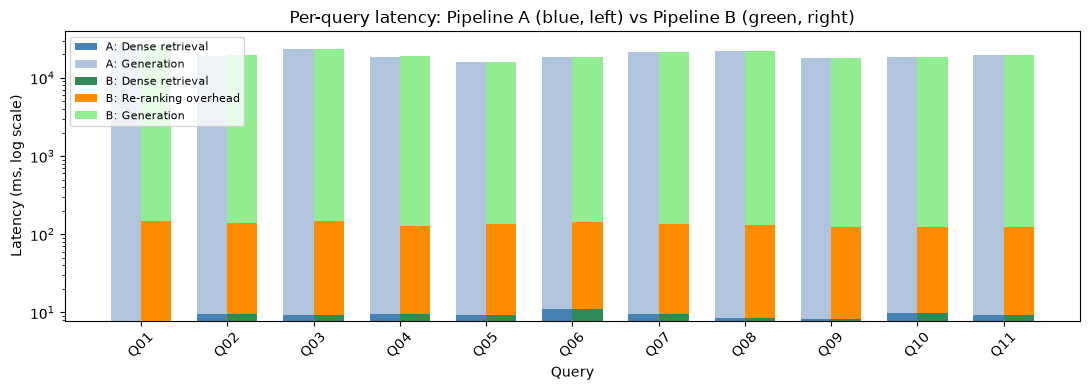

Saved: results/latency_chart.png

Note: y-axis is logarithmic so the ~9.3 ms dense and ~125.0 ms re-ranking bars are visible alongside the ~20022 ms generation bars.


In [24]:
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 4))
x     = np.arange(len(lat_df))
width = 0.35

# Pipeline A (left bar): blue tones
ax.bar(x - width/2, lat_df["Dense (ms)"],    width,
       label="A: Dense retrieval",  color="steelblue")
ax.bar(x - width/2, lat_df["Generate (ms)"], width,
       label="A: Generation",       color="lightsteelblue",
       bottom=lat_df["Dense (ms)"])

# Pipeline B (right bar): green tones + orange re-ranking overhead
ax.bar(x + width/2, lat_df["Dense (ms)"],    width,
       label="B: Dense retrieval",  color="seagreen")
ax.bar(x + width/2, lat_df["Re-rank (ms)"],  width,
       label="B: Re-ranking overhead", color="darkorange",
       bottom=lat_df["Dense (ms)"])
ax.bar(x + width/2, lat_df["Generate (ms)"], width,
       label="B: Generation",       color="lightgreen",
       bottom=lat_df["Dense (ms)"] + lat_df["Re-rank (ms)"])

ax.set_xlabel("Query")
ax.set_ylabel("Latency (ms, log scale)")
ax.set_yscale("log")   # log scale so the tiny dense/rerank bars are visible alongside generation
ax.set_title("Per-query latency: Pipeline A (blue, left) vs Pipeline B (green, right)")
ax.set_xticks(x)
ax.set_xticklabels(lat_df["Query"], rotation=45)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("results/latency_chart.png", dpi=120)
plt.show()
print("Saved: results/latency_chart.png")
print(
    f"\nNote: y-axis is logarithmic so the "
    f"~{lat_df['Dense (ms)'].mean():.1f} ms dense and "
    f"~{lat_df['Re-rank (ms)'].mean():.1f} ms re-ranking bars are "
    f"visible alongside the "
    f"~{lat_df['Generate (ms)'].mean():.0f} ms generation bars."
)


## Section 11 — Optional Quantitative Metrics

### Recall@10, Hit@3, and MRR@3

**Recall@10:** did the bi-encoder retrieve the relevant chunk in the Top-10?
If < 1.0, re-ranking cannot help for those queries.

**Hit@3 (baseline vs re-ranked):** did the relevant chunk make it into the final Top-3?
Comparing these two numbers directly shows the improvement from re-ranking.

**MRR@3 (Mean Reciprocal Rank at 3):** average of 1/rank for the first relevant
chunk found in the Top-3 context window.
rank 1 = 1.0,  rank 2 = 0.5,  rank 3 = 0.333,  not found in Top-3 = 0.

In [25]:
# Ground truth chunk IDs, verified by manually inspecting PDF pages.
#
# Q01: ck271 p142 -- prose "11 or fewer players" (Law 1.1)
# Q02: ck87  p49  -- "overs of 6 balls" (Law 17.1)
# Q03: ck75  p43  -- Law 14.1 follow-on (200 runs lead threshold)
#      ck75 is NOT in the dense Top-10 (Recall@10 = 0)
# Q04: ck89  p50  -- Law 17.6 "does not bowl two overs consecutively"
#      Query: "Can a bowler who completed the previous over bowl any part of the next over?"
#      ck89 IS in dense Top-3 at rank 3 but cross-encoder demotes it to rank 8
#      REGRESSION: Hit@3 drops from baseline=1 to reranked=0
# Q05: ck163 p87  -- Law 27.1 wicket-keeper gloves/leg-guards
# Q06: ck166 p88  -- Law 28.3.2 "award 5 Penalty runs to the batting side" (helmet penalty)
#      Query: "How many penalty runs ... protective helmet placed on the ground ..."
#      ck166 IS at dense rank 1 and rerank rank 1 -- correct retrieval both pipelines
#      Pipeline A correct; Pipeline B generation error (stated "fielding side")
# Q07: ck168 p89  -- Law 28.4 "not more than two fielders behind popping crease on leg side"
# Q08: ck119 p65  -- Law 21.2 throwing definition (elbow joint straightened in delivery swing)
#      ordering improvement: dense rank 3 -> rerank rank 1 (shift +2)
# Q09: ck107 p59  -- Law 19.5 "Fielder grounded beyond the boundary" (FC1 rescue, shift +3)
# Q10: ck196 p104 -- Law 37.2 "Not out Obstructing" (correct retrieval; both answers incomplete)
# Q11: ck136 p74  -- Law 23.3 "Leg byes not to be awarded" (FC2 rescue, shift +7)

ground_truth = {
    "Q01": [271],
    "Q02": [87],
    "Q03": [75],   # Recall@10 = 0 (ck75 not in dense Top-10)
    "Q04": [89],   # Recall@10 = 1 (rank 3), Hit@3 baseline=1, Hit@3 reranked=0
                # REGRESSION (ck89 rank 3->8) + baseline generation failure
    "Q05": [163],
    "Q06": [166],  # Recall@10 = 1 (rank 1), Hit@3 = 1 both pipelines; Pipeline B generation error
    "Q07": [168],
    "Q08": [119],  # Law 21.2 throwing definition; ordering improvement (rank 3 -> rank 1)
    "Q09": [107],  # FC1: rescued from rank 4 -> rank 1 (shift +3)
    "Q10": [196],  # correct retrieval (rank 1 both); both answers incomplete
    "Q11": [136],  # FC2: rescued from rank 8 -> rank 1 (shift +7)
}

all_query_ids = ["Q01","Q02","Q03","Q04","Q05","Q06","Q07","Q08","Q09","Q10","Q11"]

# Build one record per query so list indices never get out of sync.
per_query = []
for qid in all_query_ids:
    res = next((r for r in results if r["query_id"] == qid), None)
    gt  = set(ground_truth.get(qid, []))
    if res is None or not gt:
        per_query.append({"qid": qid, "recall10": 0, "h3b": 0, "h3r": 0,
                          "mrr3b": 0.0, "mrr3r": 0.0, "missing": True})
        continue
    ids10 = [c["chunk_id"] for c in res["candidates"]]
    idsB3 = [c["chunk_id"] for c in res["baseline_top3"]]
    idsR3 = [c["chunk_id"] for c in res["reranked_top3"]]
    def rr3(lst, rel=gt):
        for i, x in enumerate(lst, 1):
            if x in rel: return 1.0 / i
        return 0.0
    per_query.append({
        "qid":     qid,
        "recall10": int(bool(gt & set(ids10))),
        "h3b":     int(bool(gt & set(idsB3))),
        "h3r":     int(bool(gt & set(idsR3))),
        "mrr3b":   rr3(idsB3),
        "mrr3r":   rr3(idsR3),
        "missing": False,
    })

import numpy as np
r10_all    = [p["recall10"] for p in per_query]
h3b_list   = [p["h3b"]   for p in per_query]
h3r_list   = [p["h3r"]   for p in per_query]
mrr3b_list = [p["mrr3b"] for p in per_query]
mrr3r_list = [p["mrr3r"] for p in per_query]

print(f"Total queries: {len(all_query_ids)}")
print(f"Recall@10 (all {len(all_query_ids)} queries): {sum(r10_all)}/{len(r10_all)} = {np.mean(r10_all):.2f}")
print(f"  Q03: Recall@10=0 (ck75 not in dense Top-10)")
print()
print(f"Queries with verified ground truth (all {len(h3b_list)}):")
print(f"  Hit@3  baseline  : {np.mean(h3b_list):.2f}  ({sum(h3b_list)}/{len(h3b_list)})")
print(f"  Hit@3  re-ranked : {np.mean(h3r_list):.2f}  ({sum(h3r_list)}/{len(h3r_list)})")
print(f"  MRR@3  baseline  : {np.mean(mrr3b_list):.2f}")
print(f"  MRR@3  re-ranked : {np.mean(mrr3r_list):.2f}")
print()
print("Per-query breakdown:")
for p in per_query:
    qid = p["qid"]
    note = ""
    if qid == "Q09": note = " <-- FC1 rescue (ck107 shift +3)"
    elif qid == "Q11": note = " <-- FC2 rescue (ck136 shift +7)"
    elif qid == "Q04": note = " <-- REGRESSION + baseline generation failure"
    elif qid == "Q10": note = " <-- correct retrieval; both answers incomplete"
    elif qid == "Q03": note = " <-- Recall@10=0"
    elif qid == "Q06": note = " <-- correct retrieval; Pipeline B generation error"
    print(f"  {qid}: B3={p['h3b']} R3={p['h3r']}  B_mrr3={p['mrr3b']:.2f} R_mrr3={p['mrr3r']:.2f}{note}")
print()
print("NOTE on Q01: ck271 in both Top-3s. Pipeline A answered correctly.")
print("  Pipeline B abstained despite ck271 at rerank rank 1 (generation failure).")
print("  Hit@3 and MRR@3 count as 1 for both (retrieval was correct).")


Total queries: 11
Recall@10 (all 11 queries): 10/11 = 0.91
  Q03: Recall@10=0 (ck75 not in dense Top-10)

Queries with verified ground truth (all 11):
  Hit@3  baseline  : 0.73  (8/11)
  Hit@3  re-ranked : 0.82  (9/11)
  MRR@3  baseline  : 0.56
  MRR@3  re-ranked : 0.82

Per-query breakdown:
  Q01: B3=1 R3=1  B_mrr3=0.50 R_mrr3=1.00
  Q02: B3=1 R3=1  B_mrr3=1.00 R_mrr3=1.00
  Q03: B3=0 R3=0  B_mrr3=0.00 R_mrr3=0.00 <-- Recall@10=0
  Q04: B3=1 R3=0  B_mrr3=0.33 R_mrr3=0.00 <-- REGRESSION + baseline generation failure
  Q05: B3=1 R3=1  B_mrr3=1.00 R_mrr3=1.00
  Q06: B3=1 R3=1  B_mrr3=1.00 R_mrr3=1.00 <-- correct retrieval; Pipeline B generation error
  Q07: B3=1 R3=1  B_mrr3=1.00 R_mrr3=1.00
  Q08: B3=1 R3=1  B_mrr3=0.33 R_mrr3=1.00
  Q09: B3=0 R3=1  B_mrr3=0.00 R_mrr3=1.00 <-- FC1 rescue (ck107 shift +3)
  Q10: B3=1 R3=1  B_mrr3=1.00 R_mrr3=1.00 <-- correct retrieval; both answers incomplete
  Q11: B3=0 R3=1  B_mrr3=0.00 R_mrr3=1.00 <-- FC2 rescue (ck136 shift +7)

NOTE on Q01: ck271 in

## Section 12 — Limitations and Conclusions

### Why Cross-Encoder re-ranking cannot fix everything

> If the relevant chunk is at dense rank 11, the Cross-Encoder never sees it.

Re-ranking can only **reorder** what the bi-encoder retrieved.
This is why Recall@10 is the first and most important metric to check.

### Why we do not run the Cross-Encoder on the full document

The Cross-Encoder is accurate but slow: it has to read the query and each chunk
together one pair at a time. It cannot re-use pre-computed values the way the
bi-encoder can.

This document has 307 chunks. The measured re-ranking time was 125.0 ms for 10
query-chunk pairs, which works out to about 12.5 ms per pair (simple linear estimate).

Scaling that up:
- 307 chunks × 12.5 ms ≈ **3.8 seconds** per query (full document)
- 100,000 chunks ≈ **21 minutes** per query (rough linear CPU extrapolation)
- 1,000,000 chunks ≈ **3.5 hours** per query (rough linear CPU extrapolation)

These are rough estimates. Real systems use batching and faster hardware, so actual
times would be lower, but the problem of query-dependent pairwise scoring remains:
you cannot pre-compute Cross-Encoder scores at indexing time because each score
depends on the specific query.

The two-stage design solves this: the bi-encoder narrows candidates to 10, then
the Cross-Encoder scores only those 10 pairs. The bi-encoder work is done once at
indexing time; only the query vector needs to be computed fresh.

In [26]:
conclusions = f"""
CONCLUSIONS
===========

Document  : MCC Laws of Cricket (2017 Code)
Pages     : {len(pages)}
Words     : {sum(len(p['text'].split()) for p in pages):,}
Chunks    : {len(chunks)} (size={CHUNK_SIZE} words, overlap={CHUNK_OVERLAP} words, step={CHUNK_SIZE-CHUNK_OVERLAP})
Queries   : {len(evaluation_queries)} (3 sanity checks, 5 stress tests, 3 discovered)

FAILURE CASE 1 -- {FAILURE_CASE_1_ID} (re-ranking HELPED, genuine rescue):
  Query: {next(r for r in results if r['query_id']==FAILURE_CASE_1_ID)['query']}
  ck107 (page 59, Law 19.5) was at dense rank 4, just outside the baseline Top-3.
  The bi-encoder matched on general catch/boundary vocabulary shared by all top chunks.
  The cross-encoder's joint encoding detected the specific grounded-beyond-boundary
  language in ck107 and promoted it to re-rank 1 (shift = +3).
  NOT in baseline Top-3. IS in re-ranked Top-3. Genuine rescue.

FAILURE CASE 2 -- {FAILURE_CASE_2_ID} (re-ranking HELPED, genuine rescue):
  Query: {next(r for r in results if r['query_id']==FAILURE_CASE_2_ID)['query']}
  ck136 (page 74, Law 23.3 "Leg byes not to be awarded") was at dense rank 8.
  The bi-encoder retrieved index/wide-ball chunks that share surface vocabulary.
  The cross-encoder detected that Law 23.3 directly answers the not-awarded condition.
  ck136 moved from dense rank 8 to re-rank 1 (shift = +7, largest rescue in experiment).
  NOT in baseline Top-3. IS in re-ranked Top-3. Genuine rescue.
  Answer 1 was factually wrong (said "leg byes are not scored when the ball is dead").
  Answer 2 is more relevant but incomplete and partly inaccurate: it does not state
  both specific conditions from Law 23.3 (the striker neither attempted to play the
  ball nor tried to avoid being hit), and its No-ball interpretation does not
  correctly express the expected condition.

SUPPLEMENTARY FINDING -- Q10 (correct retrieval, incomplete generation, NOT a rescue):
  Query: {next(r for r in results if r['query_id']=='Q10')['query']}
  ck196 (page 104, Law 37.2) was at dense rank 1, already in both pipelines' Top-3.
  Retrieval was correct. Both answers were incomplete: they identified accidental
  obstruction and lawful wicket protection but omitted the injury-avoidance exception.
  This is a generation-completeness failure, not a retrieval failure.

SUPPLEMENTARY FINDING -- Q01 (generation failure despite correct retrieval):
  Query: {next(r for r in results if r['query_id']=='Q01')['query']}
  ck271 was at dense rank 2 (baseline Top-3) and rerank rank 1 (re-ranked Top-3).
  Pipeline A answered correctly. Pipeline B abstained ("Not available in the supplied context")
  despite ck271 at rerank rank 1. The reranker placed ck271 at rank 1, so the failure is
  in generation, not retrieval. The experiment does not establish why generation failed;
  one possible factor is the changed combination of surrounding context passages,
  but this was not directly tested.

SUPPLEMENTARY FINDING -- Q04 (baseline generation failure + re-ranking regression):
  Query: {next(r for r in results if r['query_id']=='Q04')['query']}
  ck89 (page 50, Law 17.6) was at baseline rank 3 (Hit@3=1). Pipeline A had the
  correct chunk but generated a self-contradictory answer: it stated consecutive overs
  are prohibited and then concluded the bowler could bowl part of the next over.
  The cross-encoder demoted ck89 to rerank rank 8 (Hit@3=0) and promoted ck121
  (a different bowling restriction) to rank 1. Pipeline B answered using the wrong law.
  Q04 is both a baseline generation failure and a re-ranking regression.
  A legal-domain cross-encoder would be a useful model-comparison experiment.

SUPPLEMENTARY FINDING -- Q06 (correct retrieval; Pipeline B generation error):
  Query: {next(r for r in results if r['query_id']=='Q06')['query']}
  ck166 (page 88, Law 28.3.2) was at dense rank 1 in both pipelines -- correct retrieval.
  Pipeline A correctly stated 5 penalty runs to the batting side.
  Pipeline B had a generation error: it stated the runs go to the fielding side.
  Retrieval metrics (Hit@3=1 both pipelines) are unchanged.

LATENCY (CPU, N_REPEATS=3 repetitions after warm-up; generation measured once using
         the baseline Top-3 prompt and reused as a shared estimate for both pipelines):
  Dense retrieval : {lat_df['Dense (ms)'].mean():.1f} ms mean  (std {lat_df['Dense (ms)'].std():.1f} ms)
  Re-ranking      : {lat_df['Re-rank (ms)'].mean():.1f} ms mean (std {lat_df['Re-rank (ms)'].std():.1f} ms)
  Generation      : {lat_df['Generate (ms)'].mean()/1000:.1f} s mean    (std {lat_df['Generate (ms)'].std()/1000:.1f} s)
  Pipeline A total (per query): approx {(lat_df['Dense (ms)'].mean() + lat_df['Generate (ms)'].mean())/1000:.1f} s (Dense + Generate)
  Pipeline B total (per query): approx {(lat_df['Dense (ms)'].mean() + lat_df['Re-rank (ms)'].mean() + lat_df['Generate (ms)'].mean())/1000:.1f} s (Dense + Re-rank + shared Generate, estimated)
  Re-ranking overhead: {lat_df['Re-rank (ms)'].mean() / lat_df['Total B (ms)'].mean() * 100:.1f}% of Pipeline B total.
  The {lat_df['Re-rank (ms)'].mean():.0f} ms re-ranking overhead was small relative to CPU generation latency in this experiment.
  Pipeline B total is an estimate because generation was measured once (not independently
  per pipeline). Absolute numbers are CPU-specific and not production benchmarks.

SCALING (linear CPU extrapolation):
  {len(chunks)} chunks x {lat_df['Re-rank (ms)'].mean()/TOP_K_DENSE:.1f} ms each = {len(chunks)*lat_df['Re-rank (ms)'].mean()/TOP_K_DENSE/1000:.1f} s per query (full-corpus cross-encoding).
  At 100,000 chunks: {100_000*lat_df['Re-rank (ms)'].mean()/TOP_K_DENSE/60_000:.0f} minutes per query (linear CPU extrapolation).
  At 1,000,000 chunks: {1_000_000*lat_df['Re-rank (ms)'].mean()/TOP_K_DENSE/3_600_000:.1f} hours per query (linear CPU extrapolation).
  Batching and hardware acceleration can improve throughput, but full-corpus Cross-Encoding
  still requires query-dependent processing of every evaluated query-chunk pair.

METRICS (over all {len(h3b_list)} queries with verified ground truth):
  Recall@10 (all {len(all_query_ids)} queries): {sum(r10_all)}/{len(r10_all)} = {np.mean(r10_all):.2f}
  Hit@3  baseline  : {np.mean(h3b_list):.2f}  ({sum(h3b_list)}/{len(h3b_list)})
  Hit@3  re-ranked : {np.mean(h3r_list):.2f}  ({sum(h3r_list)}/{len(h3r_list)})
  MRR@3  baseline  : {np.mean(mrr3b_list):.2f}
  MRR@3  re-ranked : {np.mean(mrr3r_list):.2f}
  (MRR@3 = mean reciprocal rank over the 3-chunk context window used for generation)

LIMITATIONS:
  1. Recall@10 ceiling: Q03 failed in both pipelines (ck75 not in dense Top-10).
     Re-ranking cannot recover evidence it was never given.
  2. MS-MARCO training mismatch: the cross-encoder was trained on web search queries and
     may not score structured legal text as reliably. Q04 (regression where ck89 was demoted
     despite being the correct chunk) may reflect this, but the cause has not been independently
     confirmed. A legal-domain cross-encoder would be a useful model-comparison experiment.
  3. CPU latency: {lat_df['Generate (ms)'].mean()/1000:.0f}s per generation is CPU-specific and not
     representative of production use. Latency ratios between components are valid
     for comparison but absolute numbers should not be taken as production benchmarks.
  4. Small evaluation set: 11 queries deliberately chosen to expose differences.
     A random sample of 100+ queries would give a more honest overall accuracy estimate.

OVERALL CONCLUSION:
  Cross-encoder re-ranking genuinely improved retrieval on two queries:
  Q09 (boundary catch, ck107 shift +3) and Q11 (leg byes not scored, ck136 shift +7).
  In both cases the bi-encoder retrieved the correct chunk in the Top-10 but ranked it
  below three wrong chunks; the cross-encoder's joint encoding promoted it to rank 1.
  The cross-encoder also caused one regression (Q04): it demoted ck89 (Law 17.6) from
  dense rank 3 to rerank rank 8. Additionally, Q04 showed a baseline generation failure:
  Pipeline A retrieved the correct chunk but produced a self-contradictory answer.
  Q06 showed a different pattern: retrieval succeeded in both pipelines, but Pipeline B
  produced a generation error (wrong beneficiary for the penalty runs).
  Re-ranking is not uniformly beneficial: it helps when the cross-encoder's joint encoding
  matches the query type, and can hurt when it does not.
"""
print(conclusions)



CONCLUSIONS

Document  : MCC Laws of Cricket (2017 Code)
Pages     : 168
Words     : 36,832
Chunks    : 307 (size=150 words, overlap=30 words, step=120)
Queries   : 11 (3 sanity checks, 5 stress tests, 3 discovered)

FAILURE CASE 1 -- Q09 (re-ranking HELPED, genuine rescue):
  Query: What makes a catch invalid if the fielder is near the boundary?
  ck107 (page 59, Law 19.5) was at dense rank 4, just outside the baseline Top-3.
  The bi-encoder matched on general catch/boundary vocabulary shared by all top chunks.
  The cross-encoder's joint encoding detected the specific grounded-beyond-boundary
  language in ck107 and promoted it to re-rank 1 (shift = +3).
  NOT in baseline Top-3. IS in re-ranked Top-3. Genuine rescue.

FAILURE CASE 2 -- Q11 (re-ranking HELPED, genuine rescue):
  Query: Under what conditions are leg byes not scored?
  ck136 (page 74, Law 23.3 "Leg byes not to be awarded") was at dense rank 8.
  The bi-encoder retrieved index/wide-ball chunks that share surface vocabu

In [27]:
# Save all results to CSV for the report.
os.makedirs("results", exist_ok=True)

lat_df.to_csv("results/latency_results.csv", index=False)
print("Saved: results/latency_results.csv")

all_ranks = pd.concat(
    [rank_shift_table(r).assign(**{"Query ID": r["query_id"]}) for r in results],
    ignore_index=True
)
all_ranks.to_csv("results/rank_shift_results.csv", index=False)
print("Saved: results/rank_shift_results.csv")
print("\nAll results saved to results/ folder.")

Saved: results/latency_results.csv
Saved: results/rank_shift_results.csv

All results saved to results/ folder.
